# 02 · Features derivadas y prueba de no-fuga

La OBT del PSet #2 ya trae, por cada uno de los 22 atributos SMART, el valor del día y 18 columnas de ventana
(media, conteos y *shift* a 7, 14 y 30 días). Este notebook agrega **dos features derivadas** y demuestra que
**ninguna usa información del futuro**:

| Feature | Dónde se calcula | Qué mide |
|---|---|---|
| `DAYS_SINCE_FIRST_SEEN` | SQL de extracción (`src/datos.py`) | Edad observada del disco: días desde su primera observación |
| `N_CRITICAL_DEGRADING_30D` | `FeaturesDerivadas`, dentro del `Pipeline` (`src/pipeline.py`) | Cuántos atributos críticos de desgaste/errores empeoraron en los últimos 30 días |

Además, el `Pipeline` aplica `log1p` con signo a todas las columnas numéricas para los modelos lineales y la MLP
(hallazgo 3 de la EDA: colas largas). No hay variables categóricas que codificar: `MODEL_CODE` es constante (solo MC1)
y `SSD_KEY` es un identificador, que nunca entra al modelo.

Igual que la EDA, todo usa **solo el período de entrenamiento/CV** (2018-01 → 2019-09).

In [1]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl_
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src import datos, pipeline as pl

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
DATOS = Path(os.environ.get("DATOS_DIR", "/datos"))
SNAPSHOT, CACHE = DATOS / "obt_mc1", DATOS / "cache_R"
FIG = Path("../docs/figuras"); FIG.mkdir(parents=True, exist_ok=True)
SEMILLA = pl.SEMILLA
T0 = time.time()

manifiesto = datos.leer_manifiesto(SNAPSHOT)
eda = json.loads(Path("../docs/eda_decisiones.json").read_text())
auc_eda = pd.read_csv("../docs/eda_pr_auc_univariada.csv", index_col=0)
eda

{'variante': 'R',
 'atributo_regla': 'R_198',
 'sentido_regla': 'alto = riesgo',
 'pr_auc_evento_regla_univariada': 0.0068,
 'pr_auc_evento_azar': 0.0016,
 'episodio_dias': 30,
 'eventos_anticipables_train': 9070,
 'prevalencia_fila_train': 0.002454,
 'dataset_sha256': 'c0b1ea5c055579e01023c006e04a040686c8a32a4f8512ceddb7070b0f2a111c'}

## 1. Datos

Se lee la **caché de modelado** (variante R elegida en la EDA): una matriz `float32` en disco construida desde el
snapshot y verificada contra su SHA-256. Un rango de fechas es un corte contiguo de filas, así que no se copia nada.

In [2]:
t = time.time()
train = datos.cargar_cache(CACHE, hasta=datos.FIN_ENTRENAMIENTO, sha_esperado=manifiesto["dataset_sha256"])
columnas = pl.columnas_modelo(train, eda["variante"])
pl.verificar_sin_fuga(columnas)  # ninguna columna de etiqueta ni identificador entra a X
print(f"{len(train):,} filas · {len(columnas)} features de la variante {eda['variante']} · {time.time()-t:.1f} s")
print("Columnas prohibidas (nunca son features):", sorted(pl.COLUMNAS_PROHIBIDAS))

PREP = pl.preparar_eventos(train["SSD_KEY"], train["OBSERVATION_DATE"], train["DAYS_TO_FAILURE"])
Y = train["TARGET_30D"].to_numpy()

def pr_auc(x, signo=1):
    x = np.asarray(x, dtype=np.float64)
    return pl.curva_evento(None, None, None, np.where(np.isnan(x), -np.inf, signo * x), prep=PREP).pr_auc

AZAR = eda["pr_auc_evento_azar"]
print(f"Referencias de la EDA: azar {AZAR} · mejor atributo ({eda['atributo_regla']}) {eda['pr_auc_evento_regla_univariada']}")

100,603,393 filas · 419 features de la variante R · 6.2 s
Columnas prohibidas (nunca son features): ['DAYS_TO_FAILURE', 'DISK_ID', 'FIRST_FAILURE_DATE', 'LABEL_STATUS', 'LAST_SEEN_DATE', 'MODEL_CODE', 'OBSERVATION_DATE', 'OBSERVATION_DATE_KEY', 'SMART_DAILY_KEY', 'SSD_KEY', 'TARGET_30D']


Referencias de la EDA: azar 0.0016 · mejor atributo (R_198) 0.0068


## 2. Feature 1 · `DAYS_SINCE_FIRST_SEEN` (edad observada del disco)

**Por qué.** La EDA mostró que el parque envejece y falla más (hallazgo 2: la edad mediana pasa de 81 a 563 días
mientras la prevalencia se multiplica por 7,6). Las fallas de SSD siguen una curva de "bañera": hay más fallas al
principio (mortalidad infantil) y al final de la vida útil. La edad le da al modelo esa posición en la curva.

**Cómo se calcula (sin fuga).** En el SQL de extracción, **antes** de filtrar las filas con etiqueta:

```sql
DATEDIFF('day',
         MIN("OBSERVATION_DATE") OVER (PARTITION BY "SSD_KEY" ORDER BY "OBSERVATION_DATE"
                                       ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW),
         "OBSERVATION_DATE")
```

El marco de la ventana termina en la fila actual: solo ve el pasado. Se calcula antes del filtro de etiquetas para
que la edad cuente desde la primera observación real del disco, aunque esa fila no tenga etiqueta.

In [3]:
print(datos.sql_extraccion("<OBT>", ["R_5"]))

SELECT
        "SSD_KEY",
        "OBSERVATION_DATE",
        "DAYS_TO_FAILURE"::FLOAT AS "DAYS_TO_FAILURE",
        "TARGET_30D"::FLOAT AS "TARGET_30D",
        "DAYS_SINCE_FIRST_SEEN"::FLOAT AS "DAYS_SINCE_FIRST_SEEN",
        "R_5"::FLOAT AS "R_5"
FROM (
    SELECT o.*,
           DATEDIFF(
               'day',
               MIN("OBSERVATION_DATE") OVER (
                   PARTITION BY "SSD_KEY" ORDER BY "OBSERVATION_DATE"
                   ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
               ),
               "OBSERVATION_DATE"
           ) AS "DAYS_SINCE_FIRST_SEEN"
    FROM <OBT> o
)
WHERE "TARGET_30D" IS NOT NULL


PR-AUC por evento de la edad: 0.0043 = 2.7× el azar


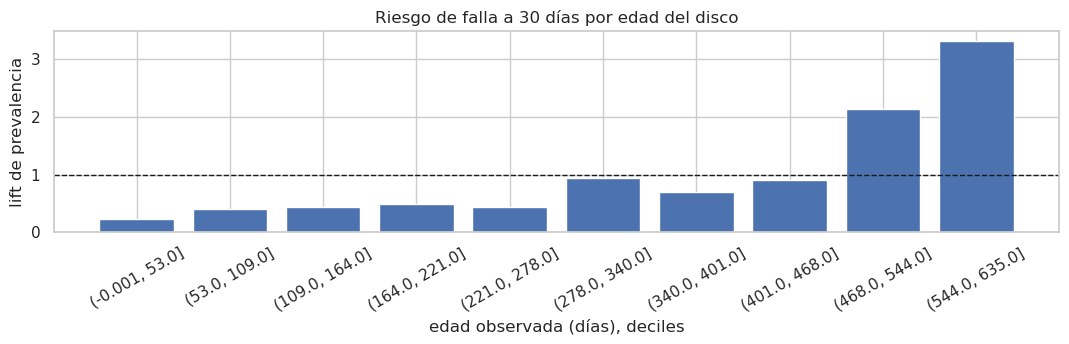

,filas,positivas,prevalencia,lift
tramo,,,,
"(-0.001, 53.0]",10064020,5748,0.0006,0.2327
"(53.0, 109.0]",10179082,10057,0.0010,0.4026
"(109.0, 164.0]",9942700,10552,0.0011,0.4324
"(164.0, 221.0]",10143007,12283,0.0012,0.4934
"(221.0, 278.0]",10002326,10724,0.0011,0.4369
"(278.0, 340.0]",10047646,23062,0.0023,0.9352
"(340.0, 401.0]",10113954,17270,0.0017,0.6958
"(401.0, 468.0]",9995633,22387,0.0022,0.9126
"(468.0, 544.0]",10057316,52848,0.0053,2.1411


In [4]:
edad = train[datos.FEATURE_EDAD].to_numpy()
cortes = np.unique(np.nanquantile(edad, np.linspace(0, 1, 11)))
tramo = pd.cut(edad, cortes, include_lowest=True)
por_edad = (pd.DataFrame({"tramo": tramo, "y": Y})
            .groupby("tramo", observed=True)["y"].agg(filas="size", positivas="sum", prevalencia="mean"))
por_edad["lift"] = por_edad["prevalencia"] / Y.mean()

auc_edad = pr_auc(edad)
print(f"PR-AUC por evento de la edad: {auc_edad:.4f} = {auc_edad / AZAR:.1f}× el azar")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(por_edad.index.astype(str), por_edad["lift"], color="#4C72B0")
ax.axhline(1, color="k", lw=1, ls="--")
ax.set_ylabel("lift de prevalencia"); ax.set_xlabel("edad observada (días), deciles")
ax.set_title("Riesgo de falla a 30 días por edad del disco")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(FIG / "02_lift_por_edad.png", dpi=150); plt.show()
por_edad

### 2.1 Prueba de no-fuga de la edad

Si la edad solo usa el pasado, entonces `fecha − edad` es **la misma fecha para todas las filas de un disco** (su
primera observación), y esa fecha es **anterior o igual** a su primera fila con etiqueta. Si dependiera del futuro
(por ejemplo, de la última fecha o de la fecha de falla), ese valor cambiaría entre filas o caería después.

In [5]:
codigos = pl.codigos_disco(train["SSD_KEY"])
fecha_dias = pl.dias_desde_epoca(train["OBSERVATION_DATE"])
origen = fecha_dias - edad.astype(np.int64)
g = pd.DataFrame({"disco": codigos, "origen": origen, "fecha": fecha_dias}).groupby("disco")
resumen = g.agg(origenes=("origen", "nunique"), origen=("origen", "first"), primera_fila=("fecha", "min"))
n_constante = int((resumen["origenes"] == 1).sum())
n_pasado = int((resumen["origen"] <= resumen["primera_fila"]).sum())
print(f"Discos: {len(resumen):,}")
print(f"  'fecha − edad' constante en todo el disco: {n_constante:,} ({n_constante/len(resumen):.4%})")
print(f"  origen ≤ primera fila con etiqueta:       {n_pasado:,} ({n_pasado/len(resumen):.4%})")
print(f"  discos cuyo origen es anterior a su primera fila etiquetada: "
      f"{int((resumen['origen'] < resumen['primera_fila']).sum()):,} (su primera observación no tenía etiqueta)")
assert n_constante == len(resumen) and n_pasado == len(resumen), "La edad dependería del futuro"

Discos: 195,493
  'fecha − edad' constante en todo el disco: 195,493 (100.0000%)
  origen ≤ primera fila con etiqueta:       195,493 (100.0000%)
  discos cuyo origen es anterior a su primera fila etiquetada: 3 (su primera observación no tenía etiqueta)


## 3. Feature 2 · `N_CRITICAL_DEGRADING_30D` (atributos críticos empeorando)

**Por qué.** En la EDA, la señal más fuerte estaba en los contadores de errores y sectores (R_198, R_5, R_187,
R_197), y para varios la **tendencia** (`MEAN_SHIFT`) superaba al valor del día (hallazgo 5). Pero cada atributo por
separado es débil: un disco puede degradarse por cualquiera de ellos. Esta feature los resume en una sola cifra:

$$N\_CRITICAL\_DEGRADING\_30D(t) = \sum_{a \in \text{críticos}} \mathbb{1}\left[R\_a\_MEAN\_SHIFT\_30D(t) > 0\right]$$

`MEAN_SHIFT_30D` es la media de los días [t−29, t] menos la de [t−59, t−30]: mayor que 0 significa que el contador
creció en el último mes. Los atributos críticos son 5, 171, 172, 183, 184, 187, 197, 198 y 199 (reasignados,
errores de programa/borrado, errores no corregibles, timeouts, pendientes y no corregibles). Se excluyen 170 y 196
porque la EDA mostró que son copias exactas de 5, y 206 porque es copia de 171: se contarían dos veces.

Vive dentro del `Pipeline` (`FeaturesDerivadas`): se calcula igual en entrenamiento, validación, prueba e inferencia.

PR-AUC por evento de N_CRITICAL_DEGRADING_30D: 0.0032 = 2.0× el azar
Cada MEAN_SHIFT_30D crítico por separado:
R_5_MEAN_SHIFT_30D     0.0061
R_198_MEAN_SHIFT_30D   0.0035
R_187_MEAN_SHIFT_30D   0.0027
R_199_MEAN_SHIFT_30D   0.0018
R_171_MEAN_SHIFT_30D   0.0017
R_183_MEAN_SHIFT_30D   0.0017
R_172_MEAN_SHIFT_30D   0.0017
R_184_MEAN_SHIFT_30D   0.0017
R_197_MEAN_SHIFT_30D   0.0017


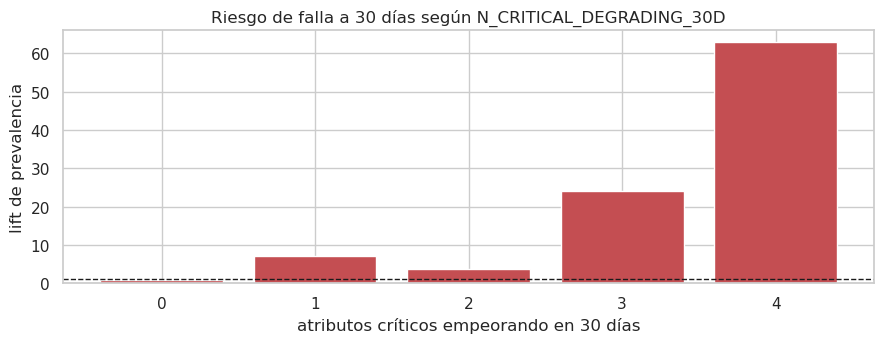

,filas,positivas,prevalencia,pct_filas,lift
n_degradando,,,,,
0,97072813,200240,0.0021,96.4906,0.8405
1,1667227,28634,0.0172,1.6572,6.9980
2,1838259,16529,0.0090,1.8272,3.6638
3,24893,1469,0.0590,0.0247,24.0453
4,201,31,0.1542,0.0002,62.8423


In [6]:
cols_shift = [f"R_{a}_MEAN_SHIFT_30D" for a in pl.ATRIBUTOS_CRITICOS_DEFECTO]
deriv = pl.FeaturesDerivadas(salida="numpy").fit(train[cols_shift])
degr = deriv.transform(train[cols_shift])[:, -1]

por_valor = (pd.DataFrame({"n_degradando": degr.astype(int), "y": Y})
             .groupby("n_degradando")["y"].agg(filas="size", positivas="sum", prevalencia="mean"))
por_valor["pct_filas"] = por_valor["filas"] / len(train) * 100
por_valor["lift"] = por_valor["prevalencia"] / Y.mean()

auc_degr = pr_auc(degr)
# Comparación justa: cada componente por separado, sobre las mismas filas
componentes = pd.Series({c: pr_auc(train[c].to_numpy()) for c in cols_shift}, name="pr_auc_evento")
print(f"PR-AUC por evento de N_CRITICAL_DEGRADING_30D: {auc_degr:.4f} = {auc_degr / AZAR:.1f}× el azar")
print("Cada MEAN_SHIFT_30D crítico por separado:")
print(componentes.sort_values(ascending=False).round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(por_valor.index.astype(str), por_valor["lift"], color="#C44E52")
ax.axhline(1, color="k", lw=1, ls="--")
ax.set_xlabel("atributos críticos empeorando en 30 días"); ax.set_ylabel("lift de prevalencia")
ax.set_title("Riesgo de falla a 30 días según N_CRITICAL_DEGRADING_30D")
fig.tight_layout(); fig.savefig(FIG / "02_lift_degradacion.png", dpi=150); plt.show()
por_valor

### 3.1 Prueba de no-fuga de la degradación

Dos niveles:

1. **La feature es fila a fila.** Calcularla sobre los datos truncados en una fecha de corte da exactamente el mismo
   valor, para las filas anteriores al corte, que calcularla con todo el período: no mira otras filas.
2. **Sus insumos solo miran al pasado.** Para una muestra de discos se **recalculan** `R_a_MEAN_30D` y
   `R_a_MEAN_SHIFT_30D` desde el valor diario `R_a`, usando únicamente días ≤ t (ventanas [t−29, t] y [t−59, t−30]),
   y se comparan con las columnas de la OBT. Si el PSet #2 hubiera usado el futuro, no coincidirían.

In [7]:
corte = pd.Timestamp("2019-03-31")
antes = train["OBSERVATION_DATE"].to_numpy() <= corte.to_datetime64()
truncado = deriv.transform(train.loc[antes, cols_shift])[:, -1]
assert np.array_equal(truncado, degr[antes]), "La feature cambió al truncar el futuro"
print(f"Truncando en {corte.date()}: {antes.sum():,} filas con el mismo valor (idénticas)")

Truncando en 2019-03-31: 69,316,075 filas con el mismo valor (idénticas)


In [8]:
# Recalcular las ventanas desde el historial diario, solo con días <= t, para 500 discos.
rng = np.random.default_rng(SEMILLA)
discos = rng.choice(train["SSD_KEY"].cat.categories.to_numpy(), size=500, replace=False)
atribs = [5, 187, 198]
crudas = [f"R_{a}" for a in atribs]
obt_cols = [f"R_{a}_{s}" for a in atribs for s in ("MEAN_30D", "MEAN_SHIFT_30D")]
m = (pl_.from_pandas(train.loc[train["SSD_KEY"].isin(discos), ["SSD_KEY", "OBSERVATION_DATE"] + crudas + obt_cols]
                     .assign(SSD_KEY=lambda d: d["SSD_KEY"].astype(str)))
     .with_columns(pl_.col("OBSERVATION_DATE").cast(pl_.Date))
     .sort("SSD_KEY", "OBSERVATION_DATE"))
actual = m.rolling("OBSERVATION_DATE", period="30d", group_by="SSD_KEY").agg(
    [pl_.col(c).mean().alias(f"{c}_rec_actual") for c in crudas])
previa = m.rolling("OBSERVATION_DATE", period="30d", offset="-60d", group_by="SSD_KEY").agg(
    [pl_.col(c).mean().alias(f"{c}_rec_previa") for c in crudas])
rec = m.join(actual, on=["SSD_KEY", "OBSERVATION_DATE"]).join(previa, on=["SSD_KEY", "OBSERVATION_DATE"])

filas = []
for c in crudas:
    media = rec[f"{c}_rec_actual"].to_numpy()
    shift = media - rec[f"{c}_rec_previa"].to_numpy()
    for nombre, recalculado in ((f"{c}_MEAN_30D", media), (f"{c}_MEAN_SHIFT_30D", shift)):
        obt = rec[nombre].to_numpy().astype(np.float64)
        ambos = ~np.isnan(obt) & ~np.isnan(recalculado)
        iguales = np.isclose(obt[ambos], recalculado[ambos], rtol=1e-4, atol=1e-3)
        filas.append({"columna OBT": nombre, "filas comparadas": int(ambos.sum()),
                      "coinciden": int(iguales.sum()),
                      "% coincide": iguales.mean() * 100 if ambos.any() else np.nan})
verif = pd.DataFrame(filas).set_index("columna OBT")
print(f"{len(discos)} discos, {rec.height:,} filas")
verif

500 discos, 257,093 filas


,filas comparadas,coinciden,% coincide
columna OBT,,,
R_5_MEAN_30D,257093,257093,100.0000
R_5_MEAN_SHIFT_30D,241200,241200,100.0000
R_187_MEAN_30D,257093,257093,100.0000
R_187_MEAN_SHIFT_30D,241200,241200,100.0000
R_198_MEAN_30D,257093,257093,100.0000
R_198_MEAN_SHIFT_30D,241200,241200,100.0000


Las ventanas recalculadas con solo el pasado coinciden con la OBT, así que las columnas de ventana, y por lo tanto
`N_CRITICAL_DEGRADING_30D`, no usan información posterior a t. Si alguna fila no coincide, suele ser porque en su
ventana hay días sin etiqueta que la caché no contiene (por ejemplo, un tramo sin `TARGET_30D` en medio del
historial): en ese caso la OBT promedia **más días del pasado**, no del futuro.

## 4. Las features dentro del Pipeline

In [9]:
from sklearn import set_config
set_config(display="text")
for familia in ("xgboost", "logistica"):
    modelo = pl.construir_modelo(familia)
    print(f"--- {familia}\n{modelo}\n")

# El mismo pipeline produce la feature en cualquier conjunto (entrenamiento, validación, prueba, inferencia)
muestra = train.iloc[:1000][columnas]
prep_arbol = pl.construir_preprocesador("xgboost").fit(muestra)
salida = prep_arbol.transform(muestra)
print("Árboles:", salida.shape, salida.dtype, "· última columna = N_CRITICAL_DEGRADING_30D")
prep_lineal = pl.construir_preprocesador("logistica").fit(muestra)
print("Lineales/MLP:", prep_lineal.transform(muestra).shape, "(log1p con signo + mediana + indicador de faltante + estándar)")

--- xgboost
Pipeline(steps=[('prep',
                 Pipeline(steps=[('derivadas',
                                  FeaturesDerivadas(salida='numpy'))])),
                ('modelo',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device='cuda',
                               early_stopping_rounds=None,
                               enable_categorical=False, eval_metric='aucpr',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=

/opt/conda/lib/python3.12/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['R_1_MEAN_SHIFT_7D' 'R_1_MEAN_SHIFT_14D' 'R_1_MEAN_SHIFT_30D'
 'R_5_MEAN_SHIFT_7D' 'R_5_MEAN_SHIFT_14D' 'R_5_MEAN_SHIFT_30D'
 'R_9_MEAN_SHIFT_7D' 'R_9_MEAN_SHIFT_14D' 'R_9_MEAN_SHIFT_30D'
 'R_12_MEAN_SHIFT_7D' 'R_12_MEAN_SHIFT_14D' 'R_12_MEAN_SHIFT_30D'
 'R_170_MEAN_SHIFT_7D' 'R_170_MEAN_SHIFT_14D' 'R_170_MEAN_SHIFT_30D'
 'R_171_MEAN_SHIFT_7D' 'R_171_MEAN_SHIFT_14D' 'R_171_MEAN_SHIFT_30D'
 'R_172_MEAN_SHIFT_7D' 'R_172_MEAN_SHIFT_14D' 'R_172_MEAN_SHIFT_30D'
 'R_173_MEAN_SHIFT_7D' 'R_173_MEAN_SHIFT_14D' 'R_173_MEAN_SHIFT_30D'
 'R_174_MEAN_SHIFT_7D' 'R_174_MEAN_SHIFT_14D' 'R_174_MEAN_SHIFT_30D'
 'R_180_MEAN_SHIFT_7D' 'R_180_MEAN_SHIFT_14D' 'R_180_MEAN_SHIFT_30D'
 'R_183_MEAN_SHIFT_7D' 'R_183_MEAN_SHIFT_14D' 'R_183_MEAN_SHIFT_30D'
 'R_184_MEAN_SHIFT_7D' 'R_184_MEAN_SHIFT_14D' 'R_184_MEAN_SHIFT_30D'
 'R_187_MEAN_SHIFT_7D' 'R_187_MEAN_SHIFT_14D' 'R_187_MEAN_SHIFT_

## 5. Resumen

In [10]:
resumen = pd.DataFrame([
    {"feature": datos.FEATURE_EDAD, "dónde": "SQL de extracción", "PR-AUC por evento": auc_edad,
     "× azar": auc_edad / AZAR, "no-fuga": "fecha − edad constante por disco y ≤ primera fila"},
    {"feature": pl.FEATURE_DEGRADACION, "dónde": "FeaturesDerivadas (Pipeline)", "PR-AUC por evento": auc_degr,
     "× azar": auc_degr / AZAR, "no-fuga": "fila a fila + ventanas recalculadas con solo el pasado"},
]).set_index("feature")
Path("../docs/features_resumen.json").write_text(resumen.reset_index().to_json(orient="records", force_ascii=False, indent=2))
print(f"Tiempo total: {(time.time()-T0)/60:.1f} min")
resumen

Tiempo total: 6.0 min


,dónde,PR-AUC por evento,× azar,no-fuga
feature,,,,
DAYS_SINCE_FIRST_SEEN,SQL de extracción,0.0043,2.6668,fecha − edad constante por disco y ≤ primera fila
N_CRITICAL_DEGRADING_30D,FeaturesDerivadas (Pipeline),0.0032,2.0274,fila a fila + ventanas recalculadas con solo e...


## 6. Conclusiones

| Feature | Evidencia | No-fuga | Decisión |
|---|---|---|---|
| `DAYS_SINCE_FIRST_SEEN` | PR-AUC por evento **2,7× el azar**. La prevalencia sube con la edad: lift 0,23 en el primer decil (≤ 53 días) y **3,3** en el último (> 544 días). El riesgo se concentra en los discos más viejos | `fecha − edad` es constante en los **195.493 discos (100 %)** y nunca es posterior a la primera fila | Se incluye en todas las familias |
| `N_CRITICAL_DEGRADING_30D` | Lift **7×** con 1 atributo degradándose, **24×** con 3 y **63×** con 4. Concentra riesgo en el 3,5 % de filas con al menos uno. Por sí sola (2,0× el azar) es más débil que su mejor componente (`R_5_MEAN_SHIFT_30D`, 3,8×): su aporte es resumir en una columna la degradación simultánea de varios contadores, lo que ayuda más a los modelos lineales que a los árboles | Truncar en 2019-03-31 deja idénticas las **69,3M** filas anteriores; las ventanas `MEAN_30D` y `MEAN_SHIFT_30D` recalculadas solo con el pasado coinciden en el **100 %** de 257.093 y 241.200 filas | Se incluye dentro del `Pipeline`. Su aporte real se mide en el notebook 03 al comparar con y sin ella |

Además, `log1p` con signo, imputación por mediana con indicador de faltante y escalado estándar se aplican en el `Pipeline` solo a la logística, la MLP y TabPFN; los árboles reciben la matriz `float32` sin transformar. No hay variables categóricas: `MODEL_CODE` es constante y `SSD_KEY` nunca entra al modelo (`COLUMNAS_PROHIBIDAS`).